# PINNs for Mechanical Engineers — Tutorial 5: The Euler–Bernoulli Beam
### One equation, fourth order: the cleanest hard case in the series

*📺 Video on YouTube | 🐍 Python · PyTorch | Intermediate*

*Notebook repository: [github.com/rraj-io/PINN_for_Mechanical_Engineer](https://github.com/rraj-io/PINN_for_Mechanical_Engineer)*

---

## Series Roadmap

This series applies physics-informed neural networks to the problems mechanical engineers actually deal with — fluids, heat, solids, and the messy places where they couple. Tutorial 4 threw four coupled fields. This one does the opposite: a **single** equation, one field, no coupling — but it's *fourth order*, which turns out to be its own kind of hard. After the buoyant cavity, this is a held breath.

| # | Tutorial | Focus | Status |
|---|----------|-------|--------|
| 1 | 2D Navier–Stokes — lid-driven cavity | coupled, nonlinear flow | ✅ Published |
| 2 | 2D Steady Heat Conduction | mixed Dirichlet/Neumann BCs | ✅ Published |
| 3 | Linear Elasticity — plate with a hole | vector fields, stress concentration | ✅ Published |
| 4 | Natural Convection — buoyant cavity | multiphysics coupling | ✅ Published |
| **5** | **Euler–Bernoulli Beam** | **4th-order derivatives** | **📍 You are here** |
| 6 | Backward-Facing Step | flow separation & reattachment | Planned |
| 7 | Unsteady Vortex Shedding — cylinder wake | the hard one: unsteady + failure modes | Planned |

Every tutorial is standalone and validated against a reference solution — and this one comes full circle: the beam has an **exact analytical solution**, so for the first time since Tutorial 3 we can check the PINN against a closed form, to the last digit.

> **New to PINNs?** This series assumes you're comfortable with the fundamentals: autograd, collocation points, the residual loss, the Adam → L-BFGS recipe. If you're starting from zero — or want the build-it-from-scratch treatment in one place — the 100+ page ebook covers all of it, from your first autograd call through 1D ODEs, Poisson, and Burgers.
>
> 👉 **[Get *PINNs from Scratch* on Gumroad](https://rajrohit403.gumroad.com/l/pinn_tutorial)**

---



## 1 — What You Will Learn

By the end of this notebook you will have:

- Solved the **Euler–Bernoulli beam equation** $EI\,w''''(x) = q(x)$ with a PINN — a single 1D field $w(x)$, the transverse deflection, governed by a **fourth-order** ODE
- Taken **four nested derivatives** of the network by autograd, and seen why 4th order stresses a PINN in ways the 2nd-order problems didn't (vanishing gradients, output scaling, sensitivity to initialization)
- Handled the **four boundary conditions** a 4th-order equation demands — and learned that they come in physical pairs: **deflection** and **slope** ($w, w'$), **moment** and **shear** ($w'', w'''$), depending on how each end is supported
- Modeled a **cantilever** (fixed one end, free the other) under a uniform load, and validated against the **exact** deflection curve — including the tip deflection every mechanical engineer memorizes, $w_{\max}=qL^4/8EI$
- Recovered the engineering quantities that matter — **bending moment** $M=EI\,w''$ and **shear force** $V=EI\,w'''$ — as autograd by-products of the same solution
- Met the honest difficulty of high-order PINNs head-on: why the naive setup trains poorly, and what fixes it (non-dimensionalization, output scaling, weighting the BC terms)

**Prerequisites:** the PINN fundamentals. This is deliberately the simplest *geometry* in the mechanical-engineering arc — one dimension, one field — so it's a clean place to isolate the one genuinely new challenge: **high-order derivatives**. If you've done Tutorial 2 (second derivatives, mixed BCs), you have everything you need; the beam just pushes the derivative order from two to four. If the fundamentals feel shaky, the [*PINNs from Scratch* ebook](https://rajrohit403.gumroad.com/l/pinn_tutorial) builds them from the first autograd call.

---

## 2 — The problem and its exact solution

After four multidimensional problems, we drop to a single equation in one variable — but it's **fourth order**, which is its own kind of hard. The **Euler–Bernoulli beam equation** relates a beam's transverse deflection $w(x)$ to the distributed load $q(x)$ pressing on it:

$$EI\,\frac{d^4 w}{dx^4} = q(x),$$

where $E$ is the material's Young's modulus, $I$ the cross-section's second moment of area, and $EI$ together the **flexural rigidity** — how stiff the beam is in bending. The fourth derivative is what makes this different from everything before: the network will be differentiated *four times*.

### The cantilever under uniform load

We take the most iconic case: a **cantilever** — clamped at one end, free at the other — carrying a uniform load $q_0$ along its length (think of a diving board, or a balcony). A fourth-order equation needs **four** boundary conditions, and they come in two physical pairs:

| End | Location | Conditions | Meaning |
|-----|----------|-----------|---------|
| Fixed (wall) | $x=0$ | $w=0,\ \ w'=0$ | no deflection, no slope — the wall holds it flat |
| Free (tip) | $x=L$ | $w''=0,\ \ w'''=0$ | no bending moment, no shear — nothing pushes on the free end |

That pairing is the lesson of high-order BCs: $w$ and $w'$ are *geometric* (position and angle), while $w''$ and $w'''$ are *mechanical* — because the **bending moment** is $M=EI\,w''$ and the **shear force** is $V=EI\,w'''$. How a beam is supported decides which pair each end gets.

### Non-dimensionalizing (and why it matters here)

Before solving, we scale the problem — and for a 4th-order PINN this isn't optional housekeeping, it's what makes training work. Let $\xi=x/L$ and $W=w/w_{\text{ref}}$ with $w_{\text{ref}}=q_0L^4/EI$. The equation collapses to a clean, parameter-free form:

$$\boxed{\,W''''(\xi)=1\quad\text{on }\xi\in[0,1],\qquad W(0)=W'(0)=0,\ \ W''(1)=W'''(1)=0\,}$$

Every quantity is now $O(1)$ — no $EI\sim10^{9}$ or tiny deflections to wreck the loss scale. (This is the same discipline that saved Tutorials 3 and 4; here it's essential, because 4th derivatives amplify scale problems fastest.)

### The exact solution

Integrate $W''''=1$ four times and pin the four constants with the boundary conditions:

$$\boxed{\,W(\xi)=\dfrac{1}{24}\big(\xi^4-4\xi^3+6\xi^2\big)\,}$$

This is **exact** — a polynomial, zero truncation error — so we can check the PINN to the last digit. The validation target is the **tip deflection**:

$$W(1)=\frac{1}{24}(1-4+6)=\frac{3}{24}=\frac{1}{8}=0.125,$$

which in dimensional terms is the formula every mechanical engineer memorizes:

$$w_{\max}=\frac{q_0 L^4}{8EI}.$$

That $1/8$ is this tutorial's factor-of-3 — the single number the PINN has to reproduce. As bonus checks, the network should also recover the moment and shear profiles, $W''(\xi)=\tfrac12(\xi-1)^2$ (peaking at the wall, zero at the tip) and $W'''(\xi)=\xi-1$ (linear, zero at the tip) — the internal forces a structural engineer actually designs against.


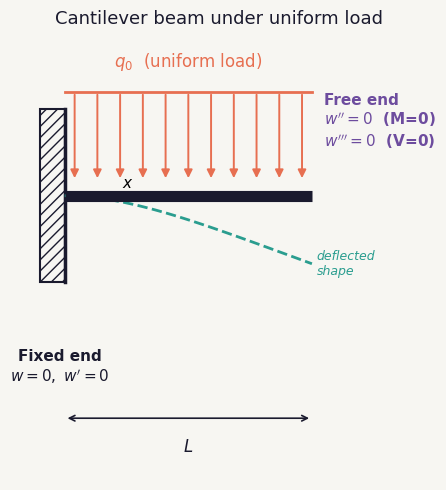

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch, Rectangle

BG="#f7f6f2"; CORAL="#E76F51"; TEAL="#2A9D8F"; INK="#1A1A2E"; PUR="#6D4C9E"
fig, ax = plt.subplots(figsize=(9, 5)); fig.patch.set_facecolor(BG); ax.set_facecolor(BG)

# clamped wall (hatched) at x < 0
ax.add_patch(Rectangle((-0.10,-0.35), 0.10, 0.70, facecolor='none', edgecolor=INK, hatch='///', lw=1.5))
ax.plot([0,0], [-0.35,0.35], color=INK, lw=2.5)

# undeformed beam
ax.plot([0,1], [0,0], color=INK, lw=8, solid_capstyle='butt', zorder=3)

# distributed load q0: arrows pushing down onto the beam
ax.plot([0,1], [0.42,0.42], color=CORAL, lw=2)
for xx in np.linspace(0.04, 0.96, 11):
    ax.add_patch(FancyArrowPatch((xx,0.42),(xx,0.06), arrowstyle='-|>', mutation_scale=12, color=CORAL, lw=1.4))
ax.text(0.5, 0.52, r"$q_0$  (uniform load)", color=CORAL, ha='center', fontsize=12)

# faint deflected shape (downward) for intuition
xi = np.linspace(0,1,100); W = (xi**4 - 4*xi**3 + 6*xi**2)/24
ax.plot(xi, -2.2*W, color=TEAL, lw=2, ls='--', zorder=2)
ax.text(1.02, -2.2*W[-1], "deflected\nshape", color=TEAL, ha='left', va='center', fontsize=9, style='italic')

# boundary-condition annotations
ax.text(-0.02, -0.62, "Fixed end\n$w=0,\\ w'=0$", color=INK, ha='center', va='top', fontsize=11, weight='bold')
ax.annotate("Free end\n$w''=0$  (M=0)\n$w'''=0$  (V=0)", xy=(1.0,0.0), xytext=(1.05,0.30),
            color=PUR, ha='left', va='center', fontsize=11, weight='bold')

# length dimension + coordinate axis
ax.annotate("", xy=(0,-0.90), xytext=(1,-0.90), arrowprops=dict(arrowstyle='<->', color=INK, lw=1.2))
ax.text(0.5, -0.98, "$L$", color=INK, ha='center', va='top', fontsize=12)
ax.add_patch(FancyArrowPatch((0,0.0),(0.22,0.0), arrowstyle='-|>', mutation_scale=12, color=INK))
ax.text(0.23, 0.03, "$x$", fontsize=11)

ax.set_xlim(-0.20,1.45); ax.set_ylim(-1.15,0.65); ax.set_aspect('equal'); ax.axis('off')
ax.set_title("Cantilever beam under uniform load", color=INK, fontsize=13, pad=8)
plt.tight_layout(); plt.show()

## 3 — Imports and Setup

Three libraries, a seed, and GPU selection. This is the shortest setup in the series: non-dimensionalizing to $W''''=1$ (Section 2) removed $E$, $I$, $q_0$, and $L$ entirely, so there are **no problem constants to define** — the domain is just $\xi\in[0,1]$ and the equation is parameter-free. That's the whole payoff of the scaling: nothing left to tune, nothing left to get wrong.

In [2]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import math, time

torch.manual_seed(0)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")
if device.type == 'cuda':
    print(f"GPU: {torch.cuda.get_device_name(0)}")

# Non-dimensional cantilever: W''''(xi) = 1 on xi in [0, 1]
#   fixed end xi=0:  W = 0, W' = 0
#   free  end xi=1:  W'' = 0, W''' = 0
# No physical constants remain — the scaling folded E, I, q0, L into W'''' = 1.
print("Problem: W'''' = 1 on [0,1] | cantilever, fixed-free | exact tip W(1) = 0.125")

Using device: cuda
GPU: Tesla T4
Problem: W'''' = 1 on [0,1] | cantilever, fixed-free | exact tip W(1) = 0.125


## 4 — The analytical reference

As in every tutorial with a closed form, we code the exact solution *first*, so ground truth is always on hand. From Section 2:

$$W(\xi)=\tfrac{1}{24}\big(\xi^4-4\xi^3+6\xi^2\big),$$

and its derivatives are the physically meaningful quantities the beam carries: the **slope** $W'$, and — up to the flexural rigidity — the **bending moment** $W''$ and **shear force** $W'''$. Coding all four gives us not just a tip number to hit but full profiles to validate against.

In [3]:
def exact_solution(xi):
    "Exact non-dimensional cantilever deflection."
    return (xi**4 - 4*xi**3 + 6*xi**2) / 24

def exact_derivatives(xi):
    "Deflection W and its derivatives: slope W', moment ~ W'', shear ~ W'''."
    W  = (xi**4 - 4*xi**3 + 6*xi**2) / 24
    W1 = (4*xi**3 - 12*xi**2 + 12*xi) / 24     # slope
    W2 = (12*xi**2 - 24*xi + 12) / 24          # = (xi-1)^2 / 2   (moment / EI-scale)
    W3 = (24*xi - 24) / 24                      # = xi - 1         (shear  / EI-scale)
    return W, W1, W2, W3

# sanity checks against the boundary conditions and the known values
xi = torch.linspace(0, 1, 101, device=device).reshape(-1, 1)
W, W1, W2, W3 = exact_derivatives(xi)
print(f"fixed end (xi=0):  W={W[0].item():.4f}  W'={W1[0].item():.4f}     (want 0, 0)")
print(f"free  end (xi=1):  W''={W2[-1].item():.4f}  W'''={W3[-1].item():.4f}   (want 0, 0)")
print(f"tip deflection W(1) = {W[-1].item():.6f}    (want 0.125 = 1/8)")
print(f"wall moment W''(0)  = {W2[0].item():.4f}      (want 0.5)")
print(f"wall shear  W'''(0) = {W3[0].item():.4f}     (want -1.0)")

fixed end (xi=0):  W=0.0000  W'=0.0000     (want 0, 0)
free  end (xi=1):  W''=0.0000  W'''=0.0000   (want 0, 0)
tip deflection W(1) = 0.125000    (want 0.125 = 1/8)
wall moment W''(0)  = 0.5000      (want 0.5)
wall shear  W'''(0) = -1.0000     (want -1.0)


## 5 — Collocation and boundary points

The beam is one-dimensional, so the sampling is the simplest in the series — and worth pausing on for exactly that reason. The "domain" is the segment $\xi\in[0,1]$, so:

- **Interior collocation points** — scattered along $(0,1)$, where we enforce the residual $W''''=1$. These carry gradients, and because the equation is 4th order they'll be differentiated *four times*.
- **Boundary points** — just the **two endpoints**. There's no line of boundary points to sample as in the 2D tutorials; a 1D domain has exactly two boundaries, each a single point. The catch is that each endpoint carries **two** conditions ($W,W'$ at the wall; $W'',W'''$ at the tip), which is how a 4th-order equation gets its four BCs from only two locations.

Every point needs gradients: the interior for the 4th-order residual, the fixed end for $W'$, the free end for $W'''$.

In [4]:
gen = torch.Generator().manual_seed(42)

N_f = 200                                                    # interior collocation points on (0,1)
xi_f = torch.rand(N_f, 1, generator=gen).to(device).requires_grad_(True)

xi_0 = torch.zeros(1, 1, device=device).requires_grad_(True) # fixed end: W=0, W'=0
xi_1 = torch.ones(1, 1, device=device).requires_grad_(True)  # free end:  W''=0, W'''=0

print(f"interior collocation points: {N_f}")
print(f"boundary points: 2 (each endpoint carries 2 of the four BCs)")

interior collocation points: 200
boundary points: 2 (each endpoint carries 2 of the four BCs)


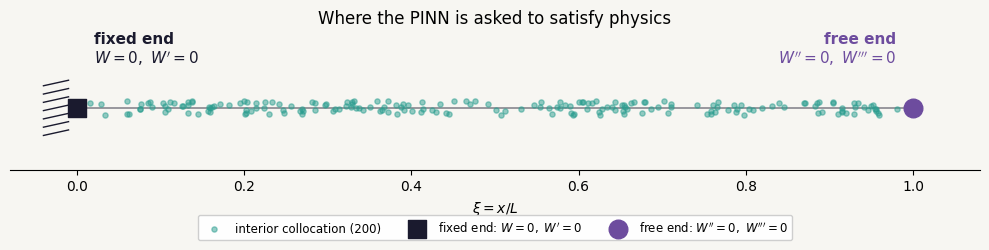

In [5]:
def np2(t): 
    return t.detach().cpu().numpy().flatten()

CORAL="#E76F51"; TEAL="#2A9D8F"; INK="#1A1A2E"; PUR="#6D4C9E"; BG="#f7f6f2"
fig, ax = plt.subplots(figsize=(10, 3.2)); fig.patch.set_facecolor(BG); ax.set_facecolor(BG)
ax.plot([0,1],[0,0], color=INK, lw=1.2, alpha=0.5, zorder=1)                       # domain line
jit = (np.random.default_rng(0).random(N_f)-0.5)*0.10                              # jitter for visibility
ax.scatter(np2(xi_f), jit, s=14, alpha=0.5, color=TEAL, zorder=2, label=f"interior collocation ({N_f})")
ax.scatter([0],[0], s=180, color=INK, marker="s", zorder=5, label="fixed end: $W=0,\\ W'=0$")
ax.scatter([1],[0], s=180, color=PUR, marker="o", zorder=5, label="free end: $W''=0,\\ W'''=0$")
ax.annotate("fixed end\n$W=0,\\ W'=0$", xy=(0,0), xytext=(0.02,0.32), color=INK, ha='left', fontsize=11, weight='bold')
ax.annotate("free end\n$W''=0,\\ W'''=0$", xy=(1,0), xytext=(0.98,0.32), color=PUR, ha='right', fontsize=11, weight='bold')
for yy in np.linspace(-0.18,0.18,7):                                              # hatched wall
    ax.plot([-0.04,-0.01],[yy-0.02,yy+0.02], color=INK, lw=1)
ax.set_xlim(-0.08,1.08); ax.set_ylim(-0.45,0.55)
ax.set_xlabel(r"$\xi = x/L$"); ax.set_yticks([])
ax.set_title("Where the PINN is asked to satisfy physics")
ax.legend(loc="lower center", bbox_to_anchor=(0.5,-0.55), ncol=3, framealpha=0.95, fontsize=8.5)
for s in ['top','right','left']: ax.spines[s].set_visible(False)
plt.tight_layout(); plt.show()

## 6 — The network (and hard-constraining the fixed end)

One input $\xi$, one output. The architecture is the smallest in the series — the exact solution is a smooth quartic, so a modest network handles it easily — but it still uses **`tanh`**, and here that matters more than ever: we take **four** derivatives, so the network must be smooth to fourth order. (A `ReLU` net would have zero third and fourth derivatives — useless.)

In [6]:
class PINN(nn.Module):
    "Input xi -> raw output N(xi)."
    def __init__(self, n_hidden=40, n_layers=3):
        super().__init__()
        layers = [nn.Linear(1, n_hidden), nn.Tanh()]
        for _ in range(n_layers - 1):
            layers += [nn.Linear(n_hidden, n_hidden), nn.Tanh()]
        layers += [nn.Linear(n_hidden, 1)]
        self.net = nn.Sequential(*layers)
        for m in self.net:
            if isinstance(m, nn.Linear):
                nn.init.xavier_normal_(m.weight)
                nn.init.zeros_(m.bias)
    def forward(self, xi):
        return self.net(xi)

model = PINN().to(device)
n_params = sum(p.numel() for p in model.parameters())
print(model)
print(f"Trainable parameters: {n_params}")

PINN(
  (net): Sequential(
    (0): Linear(in_features=1, out_features=40, bias=True)
    (1): Tanh()
    (2): Linear(in_features=40, out_features=40, bias=True)
    (3): Tanh()
    (4): Linear(in_features=40, out_features=40, bias=True)
    (5): Tanh()
    (6): Linear(in_features=40, out_features=1, bias=True)
  )
)
Trainable parameters: 3401


## 7 — Hard-constraining the fixed end

Rather than penalize the fixed-end conditions $W(0)=0$ and $W'(0)=0$ with loss terms, we build them into the output — the same idea Tutorial 4 used for no-slip. Define the deflection as:

$$W(\xi)=\xi^2\,N(\xi),$$

where $N$ is the raw network from Section 6. Because of the $\xi^2$ factor, $W(0)=0$ automatically, and since $W'=2\xi N+\xi^2 N'$, we get $W'(0)=0$ automatically too. The beam **starts clamped**, exactly, and the network only has to learn the shape — removing two of the four boundary conditions for free. Only the free end ($W''=0,\,W'''=0$) remains, as a soft loss term.

This ansatz doesn't lose the answer: the exact solution $W=\tfrac{\xi^2}{24}(\xi^2-4\xi+6)$ is already of the form $\xi^2 N$ with $N=\tfrac{1}{24}(\xi^2-4\xi+6)$ — well within the network's reach.

In [7]:
def deflection(xi):
    "Hard-constrained deflection: W = xi^2 * N(xi) enforces W(0)=0 and W'(0)=0 exactly."
    return xi**2 * model(xi)

def grad(o, i): return torch.autograd.grad(o, i, torch.ones_like(o), create_graph=True)[0]

# verify the fixed-end constraint holds before any training
xi0 = torch.zeros(1, 1, device=device, requires_grad=True)
W0 = deflection(xi0); W0x = grad(W0, xi0)
print(f"fixed end (xi=0):  W={W0.item():.2e}  W'={W0x.item():.2e}   (both exactly 0)")

fixed end (xi=0):  W=0.00e+00  W'=0.00e+00   (both exactly 0)


## 8 — The residual: four nested derivatives

The physics is a single line — $W''''=1$ — but computing it is the tutorial's entire challenge. We differentiate the network **four times**, each derivative built on the last with `create_graph=True` so the graph survives to the next:

$$r(\xi) = W''''(\xi) - 1.$$

This is the deepest derivative chain in the series. Tutorials 2–4 went to second order; the beam goes to fourth, and every level makes the autograd graph deeper and the network's high-frequency wiggles more amplified. The same four derivatives also hand us the physical profiles for free — slope $W'$, moment $W''$, shear $W'''$ — so we compute all of them in one helper.

In [8]:
def derivatives(xi):
    "Deflection and its first four derivatives: W, W', W'' (moment), W''' (shear), W'''' (load)."
    W  = deflection(xi)          # W = xi^2 * N(xi), fixed end already clamped
    W1 = grad(W,  xi)
    W2 = grad(W1, xi)
    W3 = grad(W2, xi)
    W4 = grad(W3, xi)
    return W, W1, W2, W3, W4

def residual(xi):
    "Beam residual: W'''' - 1."
    *_, W4 = derivatives(xi)
    return W4 - 1.0

# demo on the untrained network
r = residual(xi_f)
print(f"residual shape: {tuple(r.shape)}")
print(f"mean |W'''' - 1| (untrained): {r.abs().mean().item():.3e}")

residual shape: (200, 1)
mean |W'''' - 1| (untrained): 9.462e-01


## 9 — The loss

Three terms — and only because the fixed end is already hard-constrained (Section 7). The interior residual $W''''=1$, plus the two free-end conditions ($W''=0$, $W'''=0$ at $\xi=1$) that the $\xi^2$ ansatz couldn't absorb:

$$\mathcal{L} = \underbrace{\big\lVert W''''-1\big\rVert^2}_{\text{interior}} + \lambda\Big(\underbrace{\lVert W''\rVert^2_{\xi=1} + \lVert W'''\rVert^2_{\xi=1}}_{\text{free end: no moment, no shear}}\Big).$$

No fixed-end terms at all — those two boundary conditions cost zero loss because they're baked into the architecture. This is the payoff of the hard constraint: fewer competing terms, and a cleaner landscape for a 4th-order problem that would otherwise be fussy.

In [9]:
W_BC = 10.0     # weight on the free-end conditions

def compute_losses():
    *_, W4 = derivatives(xi_f)                      # interior: W'''' = 1
    loss_pde = ((W4 - 1.0)**2).mean()
    _, _, W2, W3, _ = derivatives(xi_1)             # free end: W''=0, W'''=0
    loss_bc = (W2**2).mean() + (W3**2).mean()
    return loss_pde, loss_bc

def total_loss():
    lp, lb = compute_losses()
    return lp + W_BC * lb

# demo on the untrained network
lp, lb = compute_losses()
print(f"untrained:  loss_pde={lp.item():.3e}  loss_bc={lb.item():.3e}")

untrained:  loss_pde=9.026e-01  loss_bc=7.263e-03


## 10 — Two-phase training: Adam → L-BFGS

A short Adam warm-up, then L-BFGS (the workhorse for this problem — Fowler et al. rely on it). We log the loss and the three benchmark diagnostics so you can watch convection **develop**: `u_max` and `v_max` climb from ~0, and `Nu` lifts off 1 toward 2.243 as the flow strengthens.

**This is a heavy solve** — 4th-order autograd, and convection takes many L-BFGS iterations to appear. On CPU it crawls; on a GPU it's far more comfortable. Increase the L-BFGS `max_iter` / rounds until the diagnostics plateau near the benchmark. If the flow is slow to start, that's expected — it develops gradually, not suddenly.

In [11]:
history = {"epoch": [], "pde": [], "bc": [], "Nu": [], "u_max": [], "v_max": []}

def record(epoch):
    lp, lb = compute_losses(); um, vm = peak_velocities()
    history["epoch"].append(epoch); history["pde"].append(lp.item()); history["bc"].append(lb.item())
    history["Nu"].append(nusselt_hot_wall()); history["u_max"].append(um); history["v_max"].append(vm)
    print(f"[{epoch:5d}]  pde={lp.item():.3e} bc={lb.item():.3e}  "
          f"Nu={history['Nu'][-1]:.3f}  u_max={um:.3f}  v_max={vm:.3f}")

# --- Adam warm-up ---
opt = torch.optim.Adam(model.parameters(), lr=2e-3)
ADAM_ITERS = 500
record(0)
for epoch in range(1, ADAM_ITERS + 1):
    opt.zero_grad(); total_loss().backward(); opt.step()
    if epoch % 100 == 0: record(epoch)

# --- L-BFGS refinement (run several rounds; increase until diagnostics plateau) ---
LBFGS_ROUNDS, LBFGS_ITERS = 20, 200
step = ADAM_ITERS
for r in range(LBFGS_ROUNDS):
    opt = torch.optim.LBFGS(model.parameters(), lr=1.0, max_iter=LBFGS_ITERS, max_eval=int(LBFGS_ITERS*1.3),
                            tolerance_grad=1e-12, tolerance_change=1e-14,
                            history_size=50, line_search_fn='strong_wolfe')
    def closure():
        opt.zero_grad(); L = total_loss(); L.backward(); return L
    opt.step(closure); step += LBFGS_ITERS
    record(step)
print("done — compare the final Nu / u_max / v_max against BENCHMARK[RA]")

## 11 — The Loss History, Both Phases

In [12]:
# convergence history: watch convection develop
epoch = np.array(history["epoch"])
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ax[0].semilogy(epoch, history["pde"], 'o-', color='#1A1A2E', ms=3, label='PDE residual')
ax[0].semilogy(epoch, np.maximum(history["bc"],1e-14), ':', color='#6D4C9E', label='insulated BC')
ax[0].set_xlabel('iteration'); ax[0].set_ylabel('loss'); ax[0].set_title('Loss history'); ax[0].legend(fontsize=8)
ax2 = ax[1]; ax3 = ax2.twinx()
ax2.plot(epoch, history["Nu"], 'o-', color='#2A9D8F', ms=3, label='Nu')
ax2.axhline(BENCHMARK[RA]['Nu'], ls=':', color='#2A9D8F', lw=1)
ax3.plot(epoch, history["u_max"], '^-', color='#E76F51', ms=3, alpha=0.8, label='u_max')
ax3.plot(epoch, history["v_max"], 's-', color='#3B6FB0', ms=3, alpha=0.8, label='v_max')
ax3.axhline(BENCHMARK[RA]['v_max'], ls=':', color='#3B6FB0', lw=1)
ax2.set_xlabel('iteration'); ax2.set_ylabel('Nu', color='#2A9D8F'); ax3.set_ylabel('peak velocity')
ax2.set_title('Convection developing toward the benchmark')
h1,l1=ax2.get_legend_handles_labels(); h2,l2=ax3.get_legend_handles_labels()
ax2.legend(h1+h2, l1+l2, fontsize=8, loc='center right')
plt.tight_layout(); plt.show()

## 12 — Results and validation

Compare the trained diagnostics against the benchmark,then plot the fields.

In [13]:
um, vm = peak_velocities()
b = BENCHMARK[RA]
print(f"quantity     PINN        de Vahl Davis   rel. error")
print(f"Nu          {nusselt_hot_wall():8.3f}    {b['Nu']:8.3f}      {abs(nusselt_hot_wall()-b['Nu'])/b['Nu']*100:5.1f}%")
print(f"u_max       {um:8.3f}    {b['u_max']:8.3f}      {abs(um-b['u_max'])/b['u_max']*100:5.1f}%")
print(f"v_max       {vm:8.3f}    {b['v_max']:8.3f}      {abs(vm-b['v_max'])/b['v_max']*100:5.1f}%")

In [14]:
# field contours: temperature, stream function, velocity magnitude
n = 200
gx = torch.linspace(0, 1, n, device=device)
X, Y = torch.meshgrid(gx, gx, indexing='ij')
xf = X.reshape(-1,1).requires_grad_(True); yf = Y.reshape(-1,1).requires_grad_(True)
psi, T = fields(xf, yf)
u = grad(psi, yf); v = -grad(psi, xf)
speed = torch.sqrt(u**2 + v**2)
def G(t): return t.detach().reshape(n, n).cpu().numpy()
Xn, Yn = X.cpu().numpy(), Y.cpu().numpy()

fig, ax = plt.subplots(1, 3, figsize=(15, 4.4))
for a, (D, ttl, cm) in zip(ax, [(G(T),'Temperature $T$','inferno'),
                                (G(psi),'Stream function $\\psi$','viridis'),
                                (G(speed),'Speed $|\\mathbf{u}|$','magma')]):
    cf = a.contourf(Xn, Yn, D, levels=40, cmap=cm); fig.colorbar(cf, ax=a, fraction=0.046)
    a.set_title(ttl); a.set_xlabel('x'); a.set_ylabel('y'); a.set_aspect('equal')
plt.suptitle(f'Natural convection, Ra = {RA:.0e}', y=1.02)
plt.tight_layout(); plt.show()

- **Why this converges and the primitive form doesn't.** Continuity is exact, pressure is gone, and no-slip + wall temperatures are hard-constrained — so the optimizer only has to find the interior circulation, not fight a huge pressure or discover flow from a dead-flat start. The conduction trap that stops $(u,v,p,T)$ is sidestepped by construction.
- **It develops gradually.** Convection appears as a slow, monotonic climb in `u_max`/`v_max` over many L-BFGS iterations, with `Nu` lifting off 1 only once the flow is strong enough to distort the temperature field. If your diagnostics are short of the benchmark, **train longer** (more L-BFGS rounds) before concluding anything.
- **Higher $Ra$ is harder.** At $Ra=10^5$–$10^6$ the boundary layers thin and Fowler et al. report the optimizer briefly converging to a *sign-flipped* wrong solution before finding the right one. Expect longer training and add interior points.
- **Reference.** Formulation and PINN benchmark: Fowler, McDevitt & Roy, *Sci. Rep.* **14**, 15203 (2024). Underlying CFD benchmark: de Vahl Davis, *Int. J. Numer. Methods Fluids* **3**, 249–264 (1983).


In [15]:
# --- Figure-14-style panel: all fields & derivatives from the trained (psi, T) ---
# Everything here is a SPATIAL derivative of the model's own outputs — no retraining.
# (Paper uses z for vertical; here that's y. Axes labelled X/Z to match the paper.)
n = 120                                    # GPU: 120 is fine; on CPU drop to ~50 (memory/time)
gx = torch.linspace(0, 1, n, device=device)
X, Y = torch.meshgrid(gx, gx, indexing='ij')
x = X.reshape(-1,1).requires_grad_(True); y = Y.reshape(-1,1).requires_grad_(True)

psi, T = fields(x, y)
psi_x, psi_y = grad(psi, x), grad(psi, y)
u, w = psi_y, -psi_x                        # u horizontal, w vertical
psi_xx, psi_yy = grad(psi_x, x), grad(psi_y, y)
zeta = -(psi_xx + psi_yy)
zeta_x, zeta_y = grad(zeta, x), grad(zeta, y)
zeta_xx, zeta_yy = grad(zeta_x, x), grad(zeta_y, y)
T_x, T_y = grad(T, x), grad(T, y)
T_xx, T_yy = grad(T_x, x), grad(T_y, y)
d_uzeta_x, d_wzeta_y = grad(u*zeta, x), grad(w*zeta, y)
d_uT_x,   d_wT_y     = grad(u*T, x),   grad(w*T, y)

def G(t): return t.detach().reshape(n, n).cpu().numpy()
Xn, Yn = X.cpu().numpy(), Y.cpu().numpy()

panels = [
    (psi, r'$\psi$'), (u, r'$u$'), (w, r'$w$'),
        (d_uzeta_x, r'$\partial(u\zeta)/\partial x$'), (d_wzeta_y, r'$\partial(w\zeta)/\partial z$'),
    (T, r'$T$'), (T_x, r'$\partial T/\partial x$'), (T_y, r'$\partial T/\partial z$'),
        (T_xx, r'$\partial^2 T/\partial x^2$'), (T_yy, r'$\partial^2 T/\partial z^2$'),
    (zeta, r'$\zeta$'), (zeta_xx, r'$\partial^2\zeta/\partial x^2$'), (zeta_yy, r'$\partial^2\zeta/\partial z^2$'),
        (d_uT_x, r'$\partial(uT)/\partial x$'), (d_wT_y, r'$\partial(wT)/\partial z$'),
]
fig, ax = plt.subplots(3, 5, figsize=(18, 10.5))
for a, (D, t) in zip(ax.flat, panels):
    cf = a.contourf(Xn, Yn, G(D), levels=25, cmap='jet'); fig.colorbar(cf, ax=a, fraction=0.046)
    a.set_title(t, fontsize=12); a.set_xlabel('X'); a.set_ylabel('Z'); a.set_aspect('equal')
plt.suptitle(f'Field outputs and derivatives, Ra = {RA:.0e}  (cf. Fowler et al. Fig. 14)', y=1.0)
plt.tight_layout(); plt.show()

## 13 — Exercises

1. **Turn the Rayleigh dial down.** Set `RA = 1e3` and retrain. Convection is gentler here, so it converges faster and more reliably — a good confidence-builder. Check your Nusselt number against the benchmark's 1.118 and the peak velocities against 3.649 / 3.697. This is the run to do *first* if your `Ra=1e4` solve is being stubborn.
2. **Watch the conduction trap yourself.** Temporarily replace the hard temperature constraint `T = (1-x) + sin(πx)·T0` with a plain network output `T = T0` plus *soft* loss terms for `T=1` at `x=0` and `T=0` at `x=1`. Retrain and watch `u_max`, `v_max` sit near zero — you've reintroduced the trap. Restoring the hard constraint fixes it. Nothing teaches why the formulation matters like breaking it on purpose.
3. **Push Ra up until it strains.** Take `RA` to `1e5`, then `1e6`. The thermal boundary layers thin (roughly like `Ra^{-1/4}`), so you'll need more interior points near the walls and many more L-BFGS iterations. Fowler et al. report the optimizer briefly converging to a *sign-flipped* wrong solution at high Ra before finding the right one — if your circulation comes out reversed early in training, that's the documented failure, not a bug. Report how far you get, and how the training budget scales with Ra. This is the honest on-ramp to the "PINNs and turbulence" question.
4. **Buy accuracy with points and iterations.** Raise `N_f` from 4000 toward the paper's 10,000, and increase `LBFGS_ROUNDS`. Plot your Nu / u_max / v_max error against training budget. You'll find diminishing returns — a good, honest illustration of the accuracy-vs-cost trade every PINN forces.
5. **Reproduce Figure 14 (field derivatives).** Run the 15-panel cell — it needs *no retraining*, since every panel is a spatial derivative of your trained ψ and T. Compare the pattern (ψ splitting into two cells, the boundary-layer structure in `∂T/∂x`) against the paper. Note which high-order panels (`∂²ζ`) are "dominated by outliers," exactly as the paper warns.
6. **Parametric PINN + Figure 18 (Ra sensitivities).** The advanced extension: make the network take Ra as an input `(x, y, r)` with `r = log10(Ra)`, train across a Ra range, and recover `∂ψ/∂Ra`, `∂T/∂Ra`, etc. by autograd — a single network covering the whole Ra family, with parameter sensitivities for free. This is the one benchmark that genuinely can't be faked from a fixed-Ra model.
7. **Change the aspect ratio.** Make the cavity a tall or wide rectangle (rescale the domain and the hard-constraint factor `b`). The single central cell can break into stacked cells — a qualitatively new flow, still with the same code.
8. **Change the fluid.** Swap `Pr = 0.71` (air) for water (`Pr ≈ 7`) or a liquid metal (`Pr ≈ 0.025`). Watch how the relative thickness of the thermal and velocity boundary layers changes — high `Pr` sharpens the thermal layer, low `Pr` the velocity layer. (Benchmark values change too, so you'd need a matching reference.)

## 14 — Failure modes to watch for

This tutorial has more ways to fail than any before it, and the worst one is silent — the network *looks* converged while being physically wrong. The first two rows are the ones that define this problem.

| Symptom | Cause | Fix |
|---------|-------|-----|
| **Loss drops nicely, but `u_max ≈ v_max ≈ 0` and `Nu ≈ 1`** | the **conduction trap** — the network found the trivial no-flow solution, which nearly satisfies everything | this is *the* failure of the primitive-variable form. Use the stream-function/vorticity formulation with **hard constraints** — it sidesteps the trap by construction |
| Convection never starts, even with (ψ, T) | too few L-BFGS iterations — flow develops *slowly* | **keep training.** `u_max`/`v_max` climb gradually over many rounds; `Nu` lifts off 1 only once the flow is strong. Don't judge convergence at 500 iterations |
| Circulation runs the *wrong way* (mirror image) at high Ra | the documented sign-flipped local minimum (Fowler et al.) | train longer — it usually escapes; or restart from a lower-Ra warm start |
| `NaN` loss early in training | 4th-order derivatives amplify a bad init or too-high learning rate | lower the Adam LR; confirm `tanh` (not ReLU); check the hard-constraint factor `b` isn't mis-typed |
| `Nu` and velocities plateau *below* the benchmark | under-resolved boundary layers, especially as Ra rises | add interior points; densify near the walls; raise `N_f` toward the paper's 10,000 |
| Fields look right but the numbers are off | reading the wrong benchmark | `Pr` must be **0.71** to match de Vahl Davis; changing `Pr` or the scaling invalidates the reference |
| `∂²ζ` panels look like noise with a couple of extreme spikes | fourth derivatives of the network amplify small wiggles | expected — the paper calls these "dominated by outliers." Clip the color scale by percentile; don't treat it as a bug |
| Loss stalls in L-BFGS and won't move | line search stuck in a flat region | the round-based restart (fresh optimizer each round) resets the history and frees it |

## 15 — Vocabulary

- **Natural (free) convection** — fluid motion driven by buoyancy alone, from temperature-induced density differences; no pump or external flow.
- **Boussinesq approximation** — the standard simplification for buoyant flow: density is treated as constant everywhere *except* in the buoyancy term, where its temperature variation drives the motion.
- **Stream function ($\psi$)** — a scalar whose derivatives give the velocity ($u=\partial\psi/\partial y$, $v=-\partial\psi/\partial x$); using it makes continuity exact by construction and eliminates pressure.
- **Vorticity ($\zeta$)** — the local rotation of the fluid, $\zeta=-\nabla^2\psi$; the quantity the vorticity-transport equation evolves.
- **Vorticity–stream-function formulation** — recasting the flow in terms of $(\psi,\zeta)$ instead of $(u,v,p)$; trades pressure and continuity for one higher-order equation, and is what makes this problem converge.
- **Rayleigh number ($Ra$)** — the ratio of buoyancy to diffusive damping; the dial that sets how vigorous the convection is.
- **Prandtl number ($Pr$)** — the ratio of momentum to thermal diffusivity; a fluid property (0.71 for air) that sets the relative thickness of the velocity and thermal boundary layers.
- **Nusselt number ($Nu$)** — the non-dimensional wall heat flux; $Nu=1$ is pure conduction, and values above 1 measure how much convection enhances heat transfer.
- **Buoyancy term** — the $Ra\,Pr\,\partial T/\partial x$ source in the vorticity equation; the one coupling that lets temperature drive the flow.
- **Hard constraint** — enforcing a boundary condition by building it into the network's output (e.g. $\psi=b^2\psi_0$), so it holds *exactly* rather than as a penalized loss term.
- **Conduction trap** — the trivial no-flow solution (linear temperature, $Nu\approx1$) that a naive PINN converges to and gets stuck in; a stable, wrong local minimum.
- **Differentially heated cavity** — the benchmark geometry: a square with a hot wall, an opposite cold wall, and insulated top and bottom.

## 16 — What You Have Built (and Where the Series Goes)

The first three tutorials shared a comfortable secret: the obvious formulation worked. Write the physics, sample points, minimize. This one broke that. The obvious approach — predict $(u,v,p,T)$, penalize every equation — converges to a confident, physical-looking lie: the pure-conduction solution, zero flow, $Nu=1$. The whole tutorial was learning to *not* do the obvious thing.

What made it work wasn't more capacity or more training — it was **reformulating the problem** so the network couldn't fail:

| Choice | What it buys |
|--------|-------------|
| predict $\psi$ instead of $u,v$ | continuity satisfied **exactly**, for free |
| vorticity form ($\zeta=-\nabla^2\psi$) | pressure **eliminated** — no gauge, no $O(Ra\,Pr)$ term to represent |
| hard constraints ($\psi=b^2\psi_0$, $T=1{-}x{+}\sin\pi x\,T_0$) | no-slip and wall temperatures hold **by construction** |
| scale the vorticity residual by $Ra$ | the buoyancy scale stops dominating the loss |

Each row removes a way for the optimizer to get stuck. Together they turn an intractable problem into a solvable one — and the price was a fourth-order derivative ($\nabla^2\zeta=\nabla^4\psi$) and patience.

That's the deepest lesson the series has offered so far, and it extends the throughline. Tutorial 1 changed the *residual* and the recipe held; Tutorial 2 changed the *boundary term*; Tutorial 3 moved the *unknown upstream* of the equation. Here we changed the **unknowns themselves** — the network predicts a stream function it was never asked about, and the physical variables you actually want are all downstream of it. The recipe never changed. What changes, tutorial by tutorial, is how much art goes into setting the recipe up.

**Your result** *(fill in from your GPU run against the benchmark of $Nu=2.243$, $u_{\max}=16.178$, $v_{\max}=19.617$)*: the trained model recovered $Nu \approx$ ___, $u_{\max}\approx$ ___, $v_{\max}\approx$ ___ — within ___% of de Vahl Davis. And you watched it *earn* that: convection didn't appear all at once but grew slowly under L-BFGS, $Nu$ lifting off 1 only once the circulation was strong enough to bend the temperature field. The conduction trap that swallows the naive approach was sidestepped entirely — not by fighting it, but by choosing variables that can't fall into it.

**The honest verdict on this problem:** this is where PINNs are genuinely hard, and honesty demands saying so. A finite-volume CFD code solves the differentially heated cavity in seconds and matches the benchmark to more digits than we did, and it never gets trapped. This is not the problem where PINNs win on speed or accuracy. What they *do* offer here is the thing you saw in the Figure-14 panels and the parametric extension: every derivative of the solution — vorticity, heat flux, even the sensitivity to $Ra$ itself — falls out of the same network by autograd, mesh-free, differentiable end to end. That's a different currency than raw accuracy, and it's the one the finale problems will spend.

**Where this series goes next:** Tutorial 5 keeps the fourth-order derivative you just met — $\nabla^4\psi$ — but strips everything else away. The **Euler–Bernoulli beam** is a single 4th-order ODE, $EI\,w'''' = q$, the cleanest possible setting to see how a PINN handles high-order derivatives and the boundary conditions they demand (deflection, slope, moment, shear). After the four coupled fields of this tutorial, it will feel like a held breath — before the series climbs its last two rungs: flow separation, and the unsteady vortex street where a naive forward PINN famously fails.

---

### Get the Notebook

The full series — every tutorial, with all plots and training logs — lives on GitHub:

**[github.com/rraj-io/PINN_for_Mechanical_Engineer](https://github.com/rraj-io/PINN_for_Mechanical_Engineer)**

```bash
git clone https://github.com/rraj-io/PINN_for_Mechanical_Engineer.git
cd PINN_for_Mechanical_Engineer
```

New articles and shorter notes on PINNs, neural operators, CFD, and scientific machine learning publish regularly on Substack: **[rajrohit403.substack.com](https://rajrohit403.substack.com/)**

*Reference: Fowler, McDevitt & Roy, "Physics-informed neural network simulation of thermal cavity flow," Sci. Rep. 14, 15203 (2024); de Vahl Davis, Int. J. Numer. Methods Fluids 3, 249 (1983).*

*Next up: one equation, fourth order, and the cleanest boundary conditions in the series — the bending beam. — Rohit Raj · HalfQubiX*